Early Prediction of Student Dropout and Failure Risk from Weekly Clickstream Data (OULAD)

In [2]:
# !pip install -q torch scikit-learn pandas numpy matplotlib scipy shap umap-learn joblib
import os, time, json, random, warnings, zipfile, urllib.request, datetime, copy, importlib.metadata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold, GridSearchCV
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score,
                             accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, silhouette_score)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import joblib
warnings.filterwarnings("ignore")

# ---------------- configuration ----------------
QUICK_RUN = os.environ.get("QUICK_RUN", "0") == "1" 
SEED = 42
N_WEEKS_LIST = [4, 8, 12]
N_MAIN = 8    
N_FOLDS = 3 if QUICK_RUN else 5
EPOCHS = 3 if QUICK_RUN else 40
PATIENCE = 2 if QUICK_RUN else 6
N_TREES = 50 if QUICK_RUN else 300
SOM_EPOCHS = 1 if QUICK_RUN else 8
GD_EPOCHS = 2 if QUICK_RUN else 15
OPT_EPOCHS = 3 if QUICK_RUN else 40
OPT_SEEDS = [SEED] if QUICK_RUN else [SEED, SEED + 1, SEED + 2]

DATA_DIR = Path("data/oulad")
OUT_DIR = Path("results"); FIG_DIR = OUT_DIR / "figures"; MODEL_DIR = Path("models_saved")
for p in (DATA_DIR, OUT_DIR, FIG_DIR, MODEL_DIR):
    p.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
KEY = ["code_module", "code_presentation", "id_student"]   

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=150); plt.show()

set_seed()
print("Device:", DEVICE, "| QUICK_RUN:", QUICK_RUN)

Device: cpu | QUICK_RUN: False


1. Data

In [3]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("data/oulad")

NEEDED = [
    "studentInfo.csv",
    "studentVle.csv",
    "vle.csv",
    "studentRegistration.csv"
]

missing = [f for f in NEEDED if not (DATA_DIR / f).exists()]

if missing:
    raise FileNotFoundError(
        f"Missing files: {missing}. "
        f"Please put the CSV files in: {DATA_DIR.resolve()}"
    )

# Load data
info = pd.read_csv(DATA_DIR / "studentInfo.csv")
reg = pd.read_csv(DATA_DIR / "studentRegistration.csv")
vle_meta = pd.read_csv(
    DATA_DIR / "vle.csv",
    usecols=["id_site", "activity_type"]
)
svle = pd.read_csv(
    DATA_DIR / "studentVle.csv",
    usecols=[
        "code_module", "code_presentation",
        "id_student", "id_site", "date", "sum_click"
    ],
    dtype={
        "id_student": "int32",
        "id_site": "int32",
        "date": "int16",
        "sum_click": "int32"
    }
)

print("studentInfo:", info.shape)
print("registration:", reg.shape)
print("vle:", vle_meta.shape)
print("studentVle:", svle.shape)

info.head()

studentInfo: (32593, 12)
registration: (32593, 5)
vle: (6364, 2)
studentVle: (10655280, 6)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [4]:
# OULAD_URL = "https://analyse.kmi.open.ac.uk/open-dataset/download"
# NEEDED = ["studentInfo.csv", "studentVle.csv", "vle.csv", "studentRegistration.csv"]

# def ensure_data():
#     if all((DATA_DIR / f).exists() for f in NEEDED):
#         return
#     zip_path = DATA_DIR / "oulad.zip"
#     try:
#         print("Downloading OULAD ...")
#         urllib.request.urlretrieve(OULAD_URL, zip_path)
#         with zipfile.ZipFile(zip_path) as z:
#             z.extractall(DATA_DIR)
#         for f in NEEDED:                      # move files if the zip has a sub-folder
#             if not (DATA_DIR / f).exists():
#                 found = list(DATA_DIR.rglob(f))
#                 if found: found[0].replace(DATA_DIR / f)
#     except Exception as e:
#         raise FileNotFoundError(
#             "Could not download OULAD. Download it from https://analyse.kmi.open.ac.uk/open_dataset "
#             "and put the csv files into data/oulad/") from e

# ensure_data()
# info = pd.read_csv(DATA_DIR / "studentInfo.csv")
# reg = pd.read_csv(DATA_DIR / "studentRegistration.csv")
# vle_meta = pd.read_csv(DATA_DIR / "vle.csv", usecols=["id_site", "activity_type"])
# svle = pd.read_csv(DATA_DIR / "studentVle.csv",
#                    usecols=["code_module", "code_presentation", "id_student", "id_site", "date", "sum_click"],
#                    dtype={"id_student": "int32", "id_site": "int32", "date": "int16", "sum_click": "int32"})
# print("studentInfo:", info.shape, "| registration:", reg.shape, "| vle:", vle_meta.shape, "| studentVle:", svle.shape)
# info.head() 

2. Data quality audit

Final result counts:
 final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64 

Risk rate (Withdrawn + Fail): 0.528  -> classes are almost balanced

Missing values in studentInfo:
 imd_band    1111
dtype: int64 

Duplicate student-course rows: 0
Duplicate click rows (same student, site, day): 2195960
Missing in registration:
 date_registration         45
date_unregistration    22521
dtype: int64 

Total clicks per student-course:
 count    29228.0
mean      1355.0
std       1733.5
min          1.0
50%        739.5
90%       3439.3
99%       8032.6
99.9%    14586.3
max      24139.0
Name: sum_click, dtype: float64
Students with clicks: 29228 of 32593 -> the rest have no clickstream at all


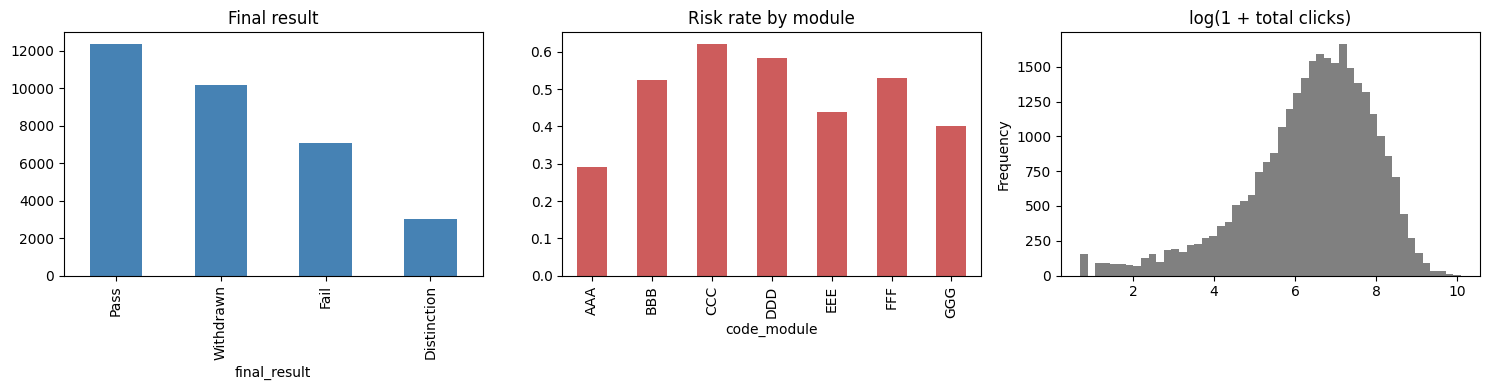

In [5]:
info["risk"] = info["final_result"].isin(["Withdrawn", "Fail"]).astype(int)

print("Final result counts:\n", info["final_result"].value_counts(), "\n")
print("Risk rate (Withdrawn + Fail): %.3f  -> classes are almost balanced\n" % info["risk"].mean())
miss = info.isna().sum(); print("Missing values in studentInfo:\n", miss[miss > 0], "\n")
print("Duplicate student-course rows:", int(info.duplicated(KEY).sum()))
print("Duplicate click rows (same student, site, day):",
      int(svle.duplicated(["code_module", "code_presentation", "id_student", "id_site", "date"]).sum()))
print("Missing in registration:\n", reg.isna().sum()[lambda s: s > 0], "\n")

tot = svle.groupby(KEY)["sum_click"].sum()
print("Total clicks per student-course:\n", tot.describe(percentiles=[.5, .9, .99, .999]).round(1))
print("Students with clicks:", len(tot), "of", len(info), "-> the rest have no clickstream at all")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
info["final_result"].value_counts().plot.bar(ax=ax[0], color="steelblue"); ax[0].set_title("Final result")
info.groupby("code_module")["risk"].mean().plot.bar(ax=ax[1], color="indianred"); ax[1].set_title("Risk rate by module")
np.log1p(tot).plot.hist(bins=50, ax=ax[2], color="gray"); ax[2].set_title("log(1 + total clicks)")
savefig("01_data_quality")
del tot

In [6]:
reg = reg[KEY + ["date_registration", "date_unregistration"]].drop_duplicates(KEY)
info = info.merge(reg, on=KEY, how="left")
info["row"] = np.arange(len(info))

W_MAX = max(N_WEEKS_LIST)
sv = svle[(svle["date"] >= 0) & (svle["date"] < W_MAX * 7)].copy()
del svle
sv["week"] = (sv["date"] // 7).astype("int16")
sv["activity_type"] = sv["id_site"].map(vle_meta.drop_duplicates("id_site").set_index("id_site")["activity_type"])

TOP_TYPES = sv.groupby("activity_type")["sum_click"].sum().sort_values(ascending=False).head(8).index.tolist()
ACT_NAMES = TOP_TYPES + ["other"]
sv["act"] = np.where(sv["activity_type"].isin(TOP_TYPES), sv["activity_type"], "other")

agg_type = sv.groupby(KEY + ["week", "act"], observed=True)["sum_click"].sum().reset_index()
agg_days = sv.groupby(KEY + ["week"], observed=True)["date"].nunique().reset_index(name="active_days")
del sv

n_rows = len(info)
rowmap = info[KEY + ["row"]]
a = agg_type.merge(rowmap, on=KEY, how="inner")
type_clicks = np.zeros((n_rows, W_MAX, len(ACT_NAMES)), dtype=np.float32)      # student x week x activity type
t_idx = a["act"].map({t: i for i, t in enumerate(ACT_NAMES)}).values.astype(int)
np.add.at(type_clicks, (a["row"].values, a["week"].values.astype(int), t_idx), a["sum_click"].values.astype(np.float32))
b = agg_days.merge(rowmap, on=KEY, how="inner")
active_days = np.zeros((n_rows, W_MAX), dtype=np.float32)                       # active days per week
active_days[b["row"].values, b["week"].values.astype(int)] = b["active_days"].values
weekly_clicks = type_clicks.sum(axis=2)
del a, b, agg_type, agg_days
print("Activity groups:", ACT_NAMES)
print("Tensors:", type_clicks.shape, active_days.shape)

Activity groups: ['forumng', 'oucontent', 'homepage', 'quiz', 'subpage', 'resource', 'url', 'ouwiki', 'other']
Tensors: (32593, 12, 9) (32593, 12)


3. Feature engineering, feature selection and datasets for each window

weeks=4   students= 27553 risk_rate=0.442 features=28 dropped(corr>0.95)=['max_weekly_clicks']
weeks=8   students= 26532 risk_rate=0.420 features=27 dropped(corr>0.95)=['max_weekly_clicks', 'clicks_homepage']
weeks=12  students= 25733 risk_rate=0.402 features=27 dropped(corr>0.95)=['max_weekly_clicks', 'clicks_homepage']


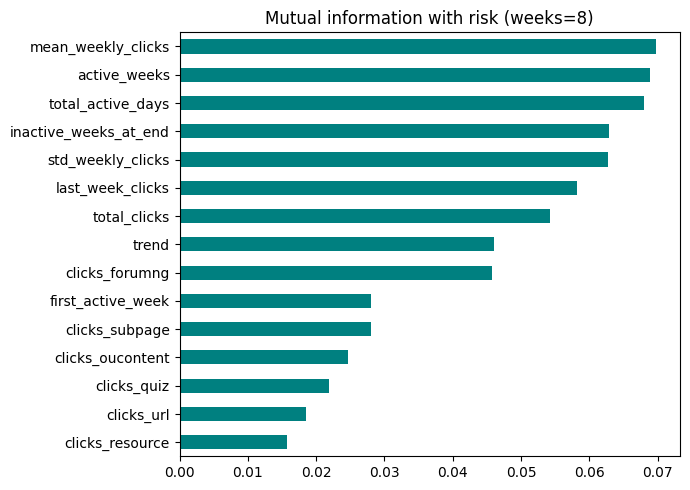

In [7]:
DEMO_NUM = ["num_of_prev_attempts", "studied_credits", "date_registration"]
CAT_COLS = ["code_module", "gender", "region", "highest_education", "imd_band", "age_band", "disability"]
CH_NAMES = ["weekly_clicks", "active_days"] + [f"clicks_{t}" for t in ACT_NAMES]

def make_dataset(N, corr_threshold=0.95):
    mask = (info["date_unregistration"].isna() | (info["date_unregistration"] >= N * 7)).values
    wc, ad, tc = weekly_clicks[mask, :N], active_days[mask, :N], type_clicks[mask, :N, :]
    base = info.loc[mask].reset_index(drop=True)
    lw = np.log1p(wc); active = wc > 0
    f = pd.DataFrame(index=base.index)
    f["total_clicks"] = np.log1p(wc.sum(1))
    f["mean_weekly_clicks"] = lw.mean(1)
    f["std_weekly_clicks"] = lw.std(1)
    f["max_weekly_clicks"] = lw.max(1)
    f["last_week_clicks"] = lw[:, -1]
    f["active_weeks"] = active.mean(1)
    f["total_active_days"] = ad.sum(1)
    f["first_active_week"] = np.where(active.any(1), active.argmax(1), N)
    f["inactive_weeks_at_end"] = np.cumprod((~active[:, ::-1]).astype(int), axis=1).sum(1)
    x = np.arange(N) - (N - 1) / 2
    f["trend"] = (lw * x).sum(1) / (x ** 2).sum()
    for i, t in enumerate(ACT_NAMES):
        f[f"clicks_{t}"] = np.log1p(tc[:, :, i].sum(1))
    corr = f.corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    dropped = [c for c in upper.columns if (upper[c] > corr_threshold).any()]
    beh_cols = [c for c in f.columns if c not in dropped]
    X = pd.concat([f[beh_cols], base[DEMO_NUM + CAT_COLS]], axis=1)
    seq = np.concatenate([lw[:, None, :], (ad / 7.0)[:, None, :], np.log1p(tc).transpose(0, 2, 1)], axis=1)
    return dict(N=N, X=X, seq=seq.astype(np.float32), y=base["risk"].values.astype(int),
                groups=base["id_student"].values, beh_cols=beh_cols, num_cols=beh_cols + DEMO_NUM,
                cat_cols=CAT_COLS, dropped=dropped, meta=base[KEY + ["final_result"]])

DATA = {N: make_dataset(N) for N in N_WEEKS_LIST}
for N, d in DATA.items():
    print(f"weeks={N:<3} students={len(d['y']):>6} risk_rate={d['y'].mean():.3f} "
          f"features={d['X'].shape[1]} dropped(corr>0.95)={d['dropped']}")
d_main = DATA[N_MAIN]

def build_preprocessor(num_cols, cat_cols):
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("vt", VarianceThreshold()), ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                    ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)])

Xmi = d_main["X"][d_main["num_cols"]].fillna(d_main["X"][d_main["num_cols"]].median())
mi = pd.Series(mutual_info_classif(Xmi, d_main["y"], random_state=SEED), index=d_main["num_cols"]).sort_values()
mi.tail(15).plot.barh(figsize=(7, 5), color="teal"); plt.title(f"Mutual information with risk (weeks={N_MAIN})")
savefig("02_mutual_information")

4. Dimensionality reduction (PCA and UMAP)

Components for 90% variance: 8 of 17
Top loadings PC1:
 {'mean_weekly_clicks': 0.33, 'total_clicks': 0.32, 'active_weeks': 0.3, 'total_active_days': 0.3}
Top loadings PC2:
 {'std_weekly_clicks': 0.57, 'first_active_week': 0.43, 'trend': 0.37, 'clicks_ouwiki': 0.28}


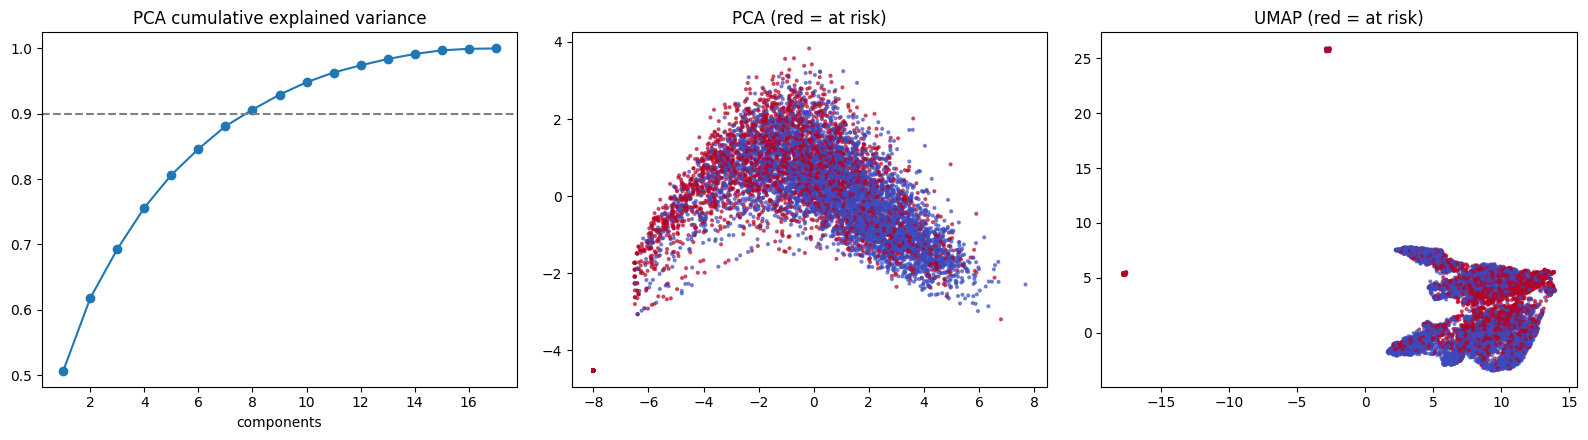

In [8]:
Xb = StandardScaler().fit_transform(d_main["X"][d_main["beh_cols"]])
pca = PCA(random_state=SEED).fit(Xb)
cum = np.cumsum(pca.explained_variance_ratio_)
n90 = int(np.searchsorted(cum, 0.90) + 1)
print(f"Components for 90% variance: {n90} of {Xb.shape[1]}")
load = pd.DataFrame(pca.components_[:2].T, index=d_main["beh_cols"], columns=["PC1", "PC2"])
print("Top loadings PC1:\n", load["PC1"].abs().sort_values(ascending=False).head(4).round(2).to_dict())
print("Top loadings PC2:\n", load["PC2"].abs().sort_values(ascending=False).head(4).round(2).to_dict())

rng = np.random.default_rng(SEED)
sub = rng.choice(len(Xb), size=min(2000 if QUICK_RUN else 8000, len(Xb)), replace=False)
Z = pca.transform(Xb)[sub]; ysub = d_main["y"][sub]

try:
    import umap
    emb = umap.UMAP(n_neighbors=30, min_dist=0.2, random_state=SEED).fit_transform(Xb[sub]); emb_name = "UMAP"
except Exception:
    from sklearn.manifold import TSNE
    emb = TSNE(n_components=2, random_state=SEED, init="pca").fit_transform(Xb[sub]); emb_name = "t-SNE"

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].plot(range(1, len(cum) + 1), cum, marker="o"); ax[0].axhline(0.9, ls="--", c="gray")
ax[0].set_title("PCA cumulative explained variance"); ax[0].set_xlabel("components")
for ax_, E, t in ((ax[1], Z[:, :2], "PCA"), (ax[2], emb, emb_name)):
    sc = ax_.scatter(E[:, 0], E[:, 1], c=ysub, cmap="coolwarm", s=4, alpha=0.6); ax_.set_title(f"{t} (red = at risk)")
savefig("03_dimensionality_reduction")

5. Validation scheme and helper functions

In [9]:
FOLD_SEED = SEED

def get_folds(data, n_splits=None):
    sgkf = StratifiedGroupKFold(n_splits=n_splits or N_FOLDS, shuffle=True, random_state=FOLD_SEED)
    return list(sgkf.split(np.zeros(len(data["y"])), data["y"], data["groups"]))

def inner_val_split(tr, y, groups, seed):
    sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=seed)
    a, b = next(sgkf.split(np.zeros(len(tr)), y[tr], groups[tr]))
    return tr[a], tr[b]

def evaluate(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return {"roc_auc": roc_auc_score(y, p), "f1": f1_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "accuracy": accuracy_score(y, pred)}

def ms(res, col): return f"{res[col].mean():.3f} ± {res[col].std():.3f}"

EXP_LOG, RESULTS = [], {}
METRICS = ["roc_auc", "f1", "precision", "recall", "accuracy"]

def log_experiment(stage, model, N, config, res):
    row = {"timestamp": datetime.datetime.now().isoformat(timespec="seconds"), "stage": stage, "model": model,
           "weeks": N, "config": json.dumps(config, default=str), "n_folds": len(res)}
    for m in METRICS:
        row[m + "_mean"] = res[m].mean(); row[m + "_std"] = res[m].std()
    if "val_auc" in res: row["val_auc_mean"] = res["val_auc"].mean()
    EXP_LOG.append(row)

def log_custom(stage, model, N, config, **metrics):
    EXP_LOG.append({"timestamp": datetime.datetime.now().isoformat(timespec="seconds"), "stage": stage,
                    "model": model, "weeks": N, "config": json.dumps(config, default=str), **metrics})

def save_log(): pd.DataFrame(EXP_LOG).to_csv(OUT_DIR / "experiment_log.csv", index=False)

def cv_run(fp, data):
    rows, extras = [], []
    oof = np.zeros(len(data["y"]))
    for k, (tr, te) in enumerate(get_folds(data)):
        proba, extra = fp(data, tr, te, SEED + k)
        oof[te] = proba
        rows.append(evaluate(data["y"][te], proba)); extras.append(extra)
    res = pd.DataFrame(rows)
    for key in (extras[0] if extras else {}):
        res[key] = [e[key] for e in extras]
    return res, oof

def run_and_log(stage, name, fp, data, config=None):
    t0 = time.time()
    res, oof = cv_run(fp, data)
    RESULTS[(name, data["N"])] = {"folds": res, "oof": oof}
    log_experiment(stage, name, data["N"], config or {}, res)
    print(f"{name:<24} weeks={data['N']:<3} AUC {ms(res, 'roc_auc')} | F1 {ms(res, 'f1')} | {time.time() - t0:.0f}s")
    return res

def prep_tabular(data, idx_list):
    """Fit the preprocessor on the first index set only, then transform all sets (no leakage)."""
    pre = build_preprocessor(data["num_cols"], data["cat_cols"])
    first = pre.fit_transform(data["X"].iloc[idx_list[0]])
    out = [first] + [pre.transform(data["X"].iloc[i]) for i in idx_list[1:]]
    return [o.astype(np.float32) for o in out], pre

6. Classical machine learning baselines

In [10]:
tr0, te0 = get_folds(d_main)[0]
def tune(model, grid):
    pipe = Pipeline([("pre", build_preprocessor(d_main["num_cols"], d_main["cat_cols"])), ("clf", model)])
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=GroupKFold(n_splits=3), n_jobs=1)
    gs.fit(d_main["X"].iloc[tr0], d_main["y"][tr0], groups=d_main["groups"][tr0])
    return gs

lr_grid = {"clf__C": [0.1, 1.0] if QUICK_RUN else [0.01, 0.1, 1.0, 10.0]}
rf_grid = {"clf__max_depth": [6, None] if QUICK_RUN else [6, 12, None],
           "clf__min_samples_leaf": [5] if QUICK_RUN else [1, 5, 20]}
gs_lr = tune(LogisticRegression(max_iter=2000), lr_grid)
gs_rf = tune(RandomForestClassifier(n_estimators=N_TREES, n_jobs=-1, random_state=SEED), rf_grid)
BEST_LR = {k.replace("clf__", ""): v for k, v in gs_lr.best_params_.items()}
BEST_RF = {k.replace("clf__", ""): v for k, v in gs_rf.best_params_.items()}
print("Best LR params:", BEST_LR, "| Best RF params:", BEST_RF)

def fp_sklearn(model_fn):
    def fp(data, tr, te, seed):
        pipe = Pipeline([("pre", build_preprocessor(data["num_cols"], data["cat_cols"])), ("clf", model_fn(seed))])
        pipe.fit(data["X"].iloc[tr], data["y"][tr])
        return pipe.predict_proba(data["X"].iloc[te])[:, 1], {}
    return fp

make_lr = lambda seed: LogisticRegression(max_iter=2000, random_state=seed, **BEST_LR)
make_rf = lambda seed: RandomForestClassifier(n_estimators=N_TREES, n_jobs=-1, random_state=seed, **BEST_RF)

for N in N_WEEKS_LIST:
    run_and_log("baselines", "LogReg", fp_sklearn(make_lr), DATA[N], BEST_LR)
    run_and_log("baselines", "RandForest", fp_sklearn(make_rf), DATA[N], BEST_RF)
save_log()

Best LR params: {'C': 0.1} | Best RF params: {'max_depth': None, 'min_samples_leaf': 5}
LogReg                   weeks=4   AUC 0.747 ± 0.005 | F1 0.618 ± 0.009 | 15s
RandForest               weeks=4   AUC 0.740 ± 0.007 | F1 0.605 ± 0.011 | 27s
LogReg                   weeks=8   AUC 0.781 ± 0.004 | F1 0.631 ± 0.005 | 11s
RandForest               weeks=8   AUC 0.777 ± 0.006 | F1 0.613 ± 0.002 | 25s
LogReg                   weeks=12  AUC 0.795 ± 0.009 | F1 0.634 ± 0.010 | 12s
RandForest               weeks=12  AUC 0.794 ± 0.008 | F1 0.619 ± 0.007 | 25s


7. Neural network rationale
8. Multilayer perceptron

In [11]:
%%writefile models.py
"""Neural network models used in the project (PyTorch)."""
import torch
import torch.nn as nn

ACTIVATIONS = {"relu": nn.ReLU, "tanh": nn.Tanh, "elu": nn.ELU, "leaky_relu": nn.LeakyReLU}


class MLP(nn.Module):
    """Fully connected network for tabular features. Output: one logit."""
    def __init__(self, in_dim, hidden=(64, 32), activation="relu", dropout=0.0):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), ACTIVATIONS[activation]()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


class CNN1D(nn.Module):
    """1D-CNN over the weekly sequence (channels x weeks) + a small branch for static features."""
    def __init__(self, n_channels, static_dim, n_filters=32, kernel_size=3, dropout=0.3, hidden=32):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(n_channels, n_filters, kernel_size, padding=kernel_size // 2), nn.ReLU(),
            nn.Conv1d(n_filters, n_filters, kernel_size, padding=kernel_size // 2), nn.ReLU())
        self.static = nn.Sequential(nn.Linear(static_dim, hidden), nn.ReLU())
        self.head = nn.Sequential(nn.Linear(2 * n_filters + hidden, hidden), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(hidden, 1))

    def forward(self, seq, static):
        h = self.conv(seq)                                    # (batch, filters, weeks)
        pooled = torch.cat([h.mean(dim=2), h.amax(dim=2)], dim=1)
        return self.head(torch.cat([pooled, self.static(static)], dim=1)).squeeze(-1)

Overwriting models.py


In [12]:
from models import MLP, CNN1D

def make_optimizer(name, params, lr, weight_decay=0.0):
    if name == "sgd":      return torch.optim.SGD(params, lr=lr, weight_decay=weight_decay)
    if name == "momentum": return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay)
    if name == "rmsprop":  return torch.optim.RMSprop(params, lr=lr, weight_decay=weight_decay)
    if name == "adam":     return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    raise ValueError(name)

def train_torch(model, Xtr, ytr, Xva, yva, optimizer="adam", lr=1e-3, weight_decay=0.0,
                batch_size=256, epochs=None, patience=None, seed=SEED):
    """Train with BCE loss. Xtr / Xva are lists of arrays (the model gets *inputs). Early stopping on validation loss."""
    epochs = epochs or EPOCHS; patience = patience or PATIENCE
    g = torch.Generator().manual_seed(seed)
    model.to(DEVICE)
    Xt = [torch.as_tensor(x, dtype=torch.float32, device=DEVICE) for x in Xtr]
    Xv = [torch.as_tensor(x, dtype=torch.float32, device=DEVICE) for x in Xva]
    yt = torch.as_tensor(ytr, dtype=torch.float32, device=DEVICE)
    yv = torch.as_tensor(yva, dtype=torch.float32, device=DEVICE)
    opt = make_optimizer(optimizer, model.parameters(), lr, weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()
    n = len(yt); bs = min(batch_size, n)
    hist = {"train_loss": [], "val_loss": [], "val_auc": [], "time": []}
    best_loss, best_state, best_ep, wait, t0 = np.inf, copy.deepcopy(model.state_dict()), 0, 0, time.time()
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, generator=g).to(DEVICE)
        run = 0.0
        for s in range(0, n, bs):
            idx = perm[s:s + bs]
            opt.zero_grad()
            loss = loss_fn(model(*[x[idx] for x in Xt]), yt[idx])
            loss.backward(); opt.step()
            run += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            lv = model(*Xv); vloss = loss_fn(lv, yv).item()
            vauc = roc_auc_score(yva, torch.sigmoid(lv).cpu().numpy())
        hist["train_loss"].append(run / n); hist["val_loss"].append(vloss)
        hist["val_auc"].append(vauc); hist["time"].append(time.time() - t0)
        if vloss < best_loss - 1e-4:
            best_loss, best_state, best_ep, wait = vloss, copy.deepcopy(model.state_dict()), ep, 0
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state)
    hist["best_epoch"] = best_ep + 1; hist["best_val_auc"] = hist["val_auc"][best_ep]
    return model, hist

def predict_proba_torch(model, inputs):
    model.eval()
    with torch.no_grad():
        x = [torch.as_tensor(i, dtype=torch.float32, device=DEVICE) for i in inputs]
        return torch.sigmoid(model(*x)).cpu().numpy()

Max gradient difference NumPy vs PyTorch autograd: 2.78e-17  (should be about 1e-10 or smaller)
NumPy MLP (64-32) test ROC-AUC on fold 1: 0.781


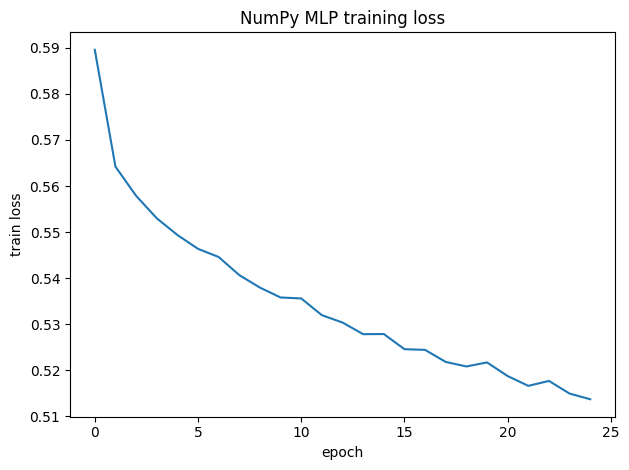

In [13]:
class NumpyMLP:
    def __init__(self, sizes, seed=0, lr=0.05, momentum=0.9):
        rng = np.random.default_rng(seed)
        self.W = [rng.normal(0, np.sqrt(2 / sizes[i]), (sizes[i], sizes[i + 1])) for i in range(len(sizes) - 1)]
        self.b = [np.zeros(sizes[i + 1]) for i in range(len(sizes) - 1)]
        self.vW = [np.zeros_like(w) for w in self.W]; self.vb = [np.zeros_like(b) for b in self.b]
        self.lr, self.momentum = lr, momentum

    @staticmethod
    def sigmoid(z): return 1 / (1 + np.exp(-np.clip(z, -30, 30)))

    def forward(self, X):
        self.a, self.z = [X], []
        L = len(self.W)
        for i in range(L):
            z = self.a[-1] @ self.W[i] + self.b[i]
            self.z.append(z)
            self.a.append(np.maximum(z, 0) if i < L - 1 else z)      # ReLU in hidden layers, logit at the end
        return self.sigmoid(self.z[-1]).ravel()

    def loss(self, p, y):
        p = np.clip(p, 1e-9, 1 - 1e-9)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

    def backward(self, y):
        L, m = len(self.W), len(y)
        dz = ((self.sigmoid(self.z[-1]).ravel() - y) / m).reshape(-1, 1)   # output error (p - y) / m
        gW, gb = [None] * L, [None] * L
        for i in reversed(range(L)):
            gW[i] = self.a[i].T @ dz
            gb[i] = dz.sum(axis=0)
            if i > 0:
                dz = (dz @ self.W[i].T) * (self.z[i - 1] > 0)                # delta(l-1) = delta(l) W^T * relu'(z)
        return gW, gb

    def step(self, gW, gb):
        for i in range(len(self.W)):
            self.vW[i] = self.momentum * self.vW[i] - self.lr * gW[i]; self.W[i] += self.vW[i]
            self.vb[i] = self.momentum * self.vb[i] - self.lr * gb[i]; self.b[i] += self.vb[i]

    def fit(self, X, y, epochs=15, batch_size=256, seed=0):
        rng = np.random.default_rng(seed); losses = []
        for ep in range(epochs):
            perm = rng.permutation(len(X)); tot = 0
            for s in range(0, len(X), batch_size):
                idx = perm[s:s + batch_size]
                p = self.forward(X[idx]); tot += self.loss(p, y[idx]) * len(idx)
                self.step(*self.backward(y[idx]))
            losses.append(tot / len(X))
        return losses

    def predict_proba(self, X): return self.forward(X)

tr0, te0 = get_folds(d_main)[0]
tr_in0, va_in0 = inner_val_split(tr0, d_main["y"], d_main["groups"], SEED)
(Xtr0, Xva0, Xte0), _ = prep_tabular(d_main, [tr_in0, va_in0, te0])
ytr0, yte0 = d_main["y"][tr_in0], d_main["y"][te0]

chk = NumpyMLP([Xtr0.shape[1], 8, 4, 1], seed=1)
xb, yb = Xtr0[:32].astype(np.float64), ytr0[:32].astype(np.float64)
chk.forward(xb); gW, gb = chk.backward(yb)
Wt = [torch.tensor(w, requires_grad=True) for w in chk.W]; bt = [torch.tensor(b, requires_grad=True) for b in chk.b]
h = torch.tensor(xb)
for i in range(len(Wt)):
    h = h @ Wt[i] + bt[i]
    if i < len(Wt) - 1: h = torch.relu(h)
torch.nn.functional.binary_cross_entropy_with_logits(h.squeeze(), torch.tensor(yb)).backward()
diff = max(max(np.abs(gW[i] - Wt[i].grad.numpy()).max(), np.abs(gb[i] - bt[i].grad.numpy()).max()) for i in range(len(Wt)))
print(f"Max gradient difference NumPy vs PyTorch autograd: {diff:.2e}  (should be about 1e-10 or smaller)")

# ---- train the NumPy MLP ----
np_mlp = NumpyMLP([Xtr0.shape[1], 64, 32, 1], seed=SEED, lr=0.02)
np_losses = np_mlp.fit(Xtr0, ytr0.astype(float), epochs=3 if QUICK_RUN else 25)
auc_np = roc_auc_score(yte0, np_mlp.predict_proba(Xte0))
print(f"NumPy MLP (64-32) test ROC-AUC on fold 1: {auc_np:.3f}")
plt.plot(np_losses); plt.xlabel("epoch"); plt.ylabel("train loss"); plt.title("NumPy MLP training loss")
savefig("04_numpy_mlp_loss")
log_custom("mlp_from_scratch", "NumpyMLP(64-32)", N_MAIN, {"lr": 0.02, "momentum": 0.9, "epochs": len(np_losses)},
           roc_auc_mean=auc_np, grad_check_max_diff=float(diff))

MLP experiments

MLP:base (64-32, relu)   weeks=8   AUC 0.783 ± 0.006 | F1 0.631 ± 0.005 | 66s
MLP:depth: 1 layer (64)  weeks=8   AUC 0.784 ± 0.005 | F1 0.631 ± 0.008 | 63s
MLP:depth: 3 layers (128-64-32) weeks=8   AUC 0.782 ± 0.005 | F1 0.630 ± 0.010 | 69s
MLP:width: 16-16         weeks=8   AUC 0.783 ± 0.005 | F1 0.627 ± 0.010 | 65s
MLP:width: 64-64         weeks=8   AUC 0.783 ± 0.004 | F1 0.632 ± 0.004 | 62s
MLP:width: 256-256       weeks=8   AUC 0.781 ± 0.005 | F1 0.627 ± 0.011 | 65s
MLP:activation: tanh     weeks=8   AUC 0.784 ± 0.005 | F1 0.629 ± 0.008 | 69s
MLP:activation: elu      weeks=8   AUC 0.784 ± 0.005 | F1 0.628 ± 0.005 | 72s
MLP:reg: dropout 0.3     weeks=8   AUC 0.784 ± 0.005 | F1 0.626 ± 0.009 | 72s
MLP:reg: weight decay 1e-3 weeks=8   AUC 0.784 ± 0.005 | F1 0.633 ± 0.004 | 61s
MLP:reg: dropout + weight decay weeks=8   AUC 0.784 ± 0.005 | F1 0.623 ± 0.007 | 74s


,val_auc,test_auc_mean,test_auc_std,test_f1,best_epoch
config,,,,,
"base (64-32, relu)",0.7881,0.7828,0.0057,0.631 ± 0.005,8.0
depth: 1 layer (64),0.7881,0.7841,0.0048,0.631 ± 0.008,15.4
depth: 3 layers (128-64-32),0.7863,0.7823,0.0046,0.630 ± 0.010,5.8
width: 16-16,0.7869,0.7830,0.0047,0.627 ± 0.010,15.8
width: 64-64,0.7870,0.7826,0.0045,0.632 ± 0.004,9.0
width: 256-256,0.7874,0.7814,0.0049,0.627 ± 0.011,4.8
activation: tanh,0.7884,0.7837,0.0048,0.629 ± 0.008,24.2
activation: elu,0.7879,0.7840,0.0046,0.628 ± 0.005,23.2
reg: dropout 0.3,0.7885,0.7838,0.0052,0.626 ± 0.009,18.0


Best MLP by validation AUC: reg: dropout + weight decay


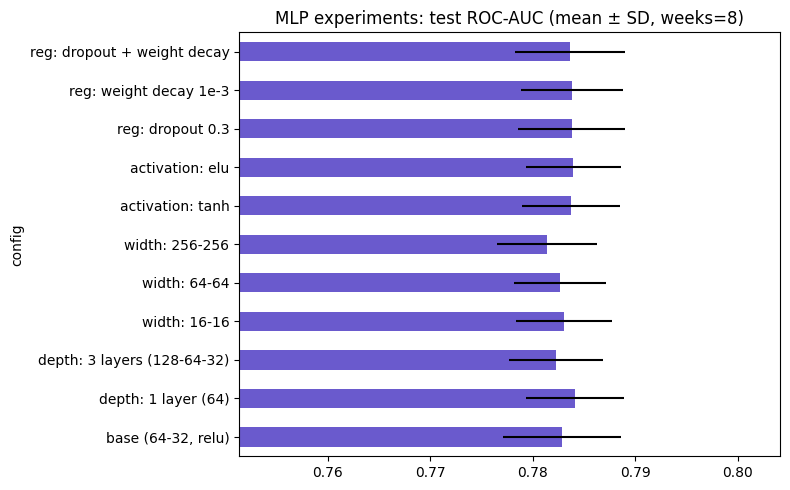

In [14]:
def fp_mlp(cfg):
    def fp(data, tr, te, seed):
        set_seed(seed)
        tr_in, va_in = inner_val_split(tr, data["y"], data["groups"], seed)
        (Xtr, Xva, Xte), _ = prep_tabular(data, [tr_in, va_in, te])
        model = MLP(Xtr.shape[1], **cfg["arch"])
        model, hist = train_torch(model, [Xtr], data["y"][tr_in], [Xva], data["y"][va_in],
                                  optimizer=cfg.get("optimizer", "adam"), lr=cfg.get("lr", 1e-3),
                                  weight_decay=cfg.get("weight_decay", 0.0), batch_size=cfg.get("batch_size", 256), seed=seed)
        return predict_proba_torch(model, [Xte]), {"val_auc": hist["best_val_auc"], "best_epoch": hist["best_epoch"]}
    return fp

def mk(hidden=(64, 32), activation="relu", dropout=0.0, weight_decay=0.0):
    return {"arch": {"hidden": hidden, "activation": activation, "dropout": dropout},
            "optimizer": "adam", "lr": 1e-3, "weight_decay": weight_decay, "batch_size": 256}

MLP_CONFIGS = {
    "base (64-32, relu)": mk(),
    "depth: 1 layer (64)": mk(hidden=(64,)),
    "depth: 3 layers (128-64-32)": mk(hidden=(128, 64, 32)),
    "width: 16-16": mk(hidden=(16, 16)),
    "width: 64-64": mk(hidden=(64, 64)),
    "width: 256-256": mk(hidden=(256, 256)),
    "activation: tanh": mk(activation="tanh"),
    "activation: elu": mk(activation="elu"),
    "reg: dropout 0.3": mk(dropout=0.3),
    "reg: weight decay 1e-3": mk(weight_decay=1e-3),
    "reg: dropout + weight decay": mk(dropout=0.3, weight_decay=1e-3),
}
rows = []
for name, cfg in MLP_CONFIGS.items():
    res = run_and_log("mlp_experiments", f"MLP:{name}", fp_mlp(cfg), d_main, cfg)
    rows.append({"config": name, "val_auc": res["val_auc"].mean(), "test_auc_mean": res["roc_auc"].mean(),
                 "test_auc_std": res["roc_auc"].std(), "test_f1": ms(res, "f1"), "best_epoch": res["best_epoch"].mean()})
mlp_table = pd.DataFrame(rows).set_index("config")
display(mlp_table.round(4))
BEST_MLP_NAME = mlp_table["val_auc"].idxmax(); BEST_MLP = MLP_CONFIGS[BEST_MLP_NAME]
print("Best MLP by validation AUC:", BEST_MLP_NAME)
RESULTS[("MLP", N_MAIN)] = RESULTS[(f"MLP:{BEST_MLP_NAME}", N_MAIN)]

mlp_table["test_auc_mean"].plot.barh(xerr=mlp_table["test_auc_std"], figsize=(8, 5), color="slateblue")
plt.xlim(mlp_table["test_auc_mean"].min() - 0.03, mlp_table["test_auc_mean"].max() + 0.02)
plt.title(f"MLP experiments: test ROC-AUC (mean ± SD, weeks={N_MAIN})")
savefig("05_mlp_experiments"); save_log()

9. Self-organizing map

SOM trained in 9s | quantization error 1.596 | topographic error 0.094


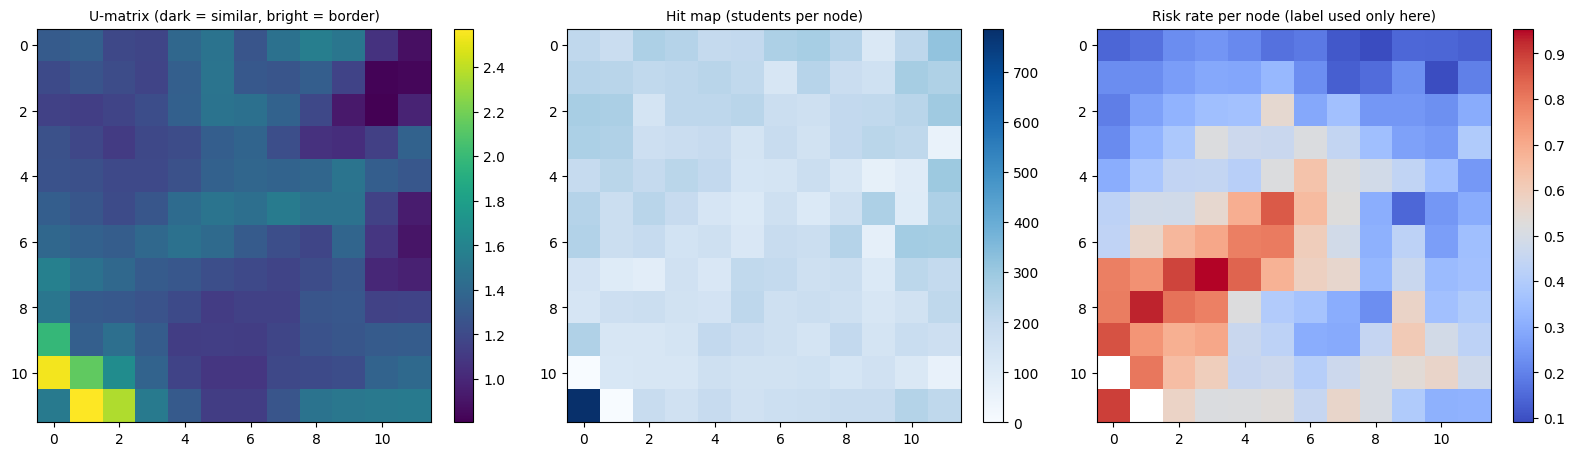

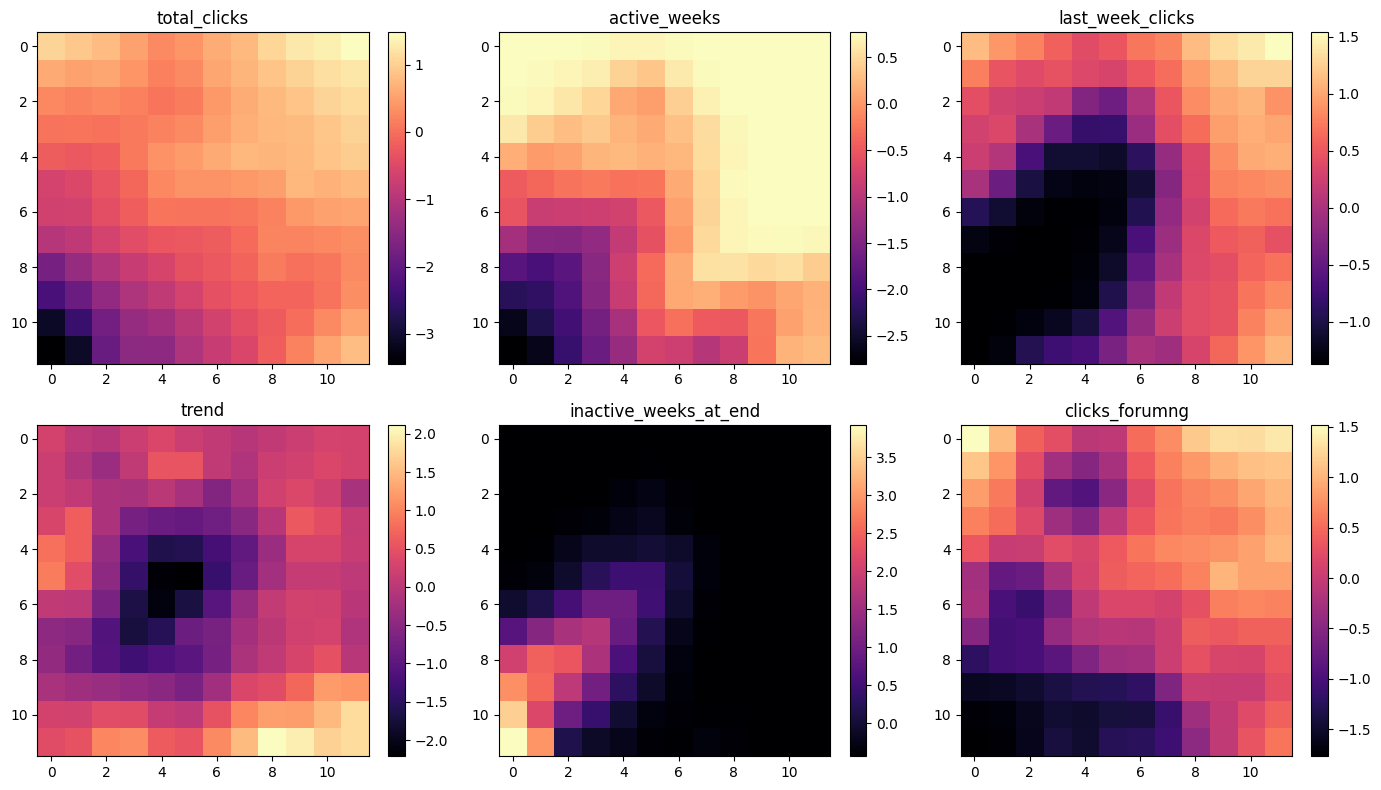

In [15]:
class SOM:
    def __init__(self, rows, cols, dim, seed=SEED):
        self.rows, self.cols = rows, cols
        self.rng = np.random.default_rng(seed)
        self.coords = np.array([(r, c) for r in range(rows) for c in range(cols)], dtype=float)
        self.d2 = ((self.coords[:, None, :] - self.coords[None, :, :]) ** 2).sum(-1)

    def fit(self, X, epochs=8, lr0=0.5, lr_end=0.01, sigma0=None, sigma_end=0.5):
        n, K = len(X), self.rows * self.cols
        sigma0 = sigma0 or max(self.rows, self.cols) / 2
        self.W = X[self.rng.choice(n, K, replace=n < K)].copy()
        total, t = epochs * n, 0
        for _ in range(epochs):
            for i in self.rng.permutation(n):
                frac = t / total
                lr = lr0 * (lr_end / lr0) ** frac; sigma = sigma0 * (sigma_end / sigma0) ** frac
                x = X[i]; j = int(np.argmin(((self.W - x) ** 2).sum(1)))
                h = np.exp(-self.d2[j] / (2 * sigma ** 2))
                self.W += lr * h[:, None] * (x - self.W)
                t += 1
        return self

    def _dist(self, X):
        return (X ** 2).sum(1)[:, None] - 2 * X @ self.W.T + (self.W ** 2).sum(1)[None, :]

    def bmu(self, X): return self._dist(X).argmin(1)

    def quality(self, X):
        d = self._dist(X)
        part = np.argpartition(d, 1, axis=1)[:, :2]
        order = np.argsort(np.take_along_axis(d, part, axis=1), axis=1)
        b1 = np.take_along_axis(part, order[:, :1], 1).ravel(); b2 = np.take_along_axis(part, order[:, 1:2], 1).ravel()
        qe = float(np.sqrt(np.maximum(d.min(1), 0)).mean())
        te = float(1 - (np.abs(self.coords[b1] - self.coords[b2]).max(1) <= 1).mean())
        return qe, te

    def u_matrix(self):
        Wg = self.W.reshape(self.rows, self.cols, -1); U = np.zeros((self.rows, self.cols))
        for r in range(self.rows):
            for c in range(self.cols):
                nb = [(r + dr, c + dc) for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1))
                      if 0 <= r + dr < self.rows and 0 <= c + dc < self.cols]
                U[r, c] = np.mean([np.linalg.norm(Wg[r, c] - Wg[a, b]) for a, b in nb])
        return U

SOM_SIZE = 12
som_cols = d_main["beh_cols"]
Xs = StandardScaler().fit_transform(d_main["X"][som_cols]).astype(np.float64)
t0 = time.time()
som = SOM(SOM_SIZE, SOM_SIZE, Xs.shape[1]).fit(Xs, epochs=SOM_EPOCHS)
qe, te_ = som.quality(Xs)
print(f"SOM trained in {time.time() - t0:.0f}s | quantization error {qe:.3f} | topographic error {te_:.3f}")
bmu = som.bmu(Xs)
y_all = d_main["y"]

hits = np.bincount(bmu, minlength=SOM_SIZE ** 2).reshape(SOM_SIZE, SOM_SIZE)
risk_sum = np.bincount(bmu, weights=y_all, minlength=SOM_SIZE ** 2)
risk_map = np.where(hits.ravel() > 0, risk_sum / np.maximum(hits.ravel(), 1), np.nan).reshape(SOM_SIZE, SOM_SIZE)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a_, M, t, cm in ((ax[0], som.u_matrix(), "U-matrix (dark = similar, bright = border)", "viridis"),
                     (ax[1], hits, "Hit map (students per node)", "Blues"),
                     (ax[2], risk_map, "Risk rate per node (label used only here)", "coolwarm")):
    im = a_.imshow(M, cmap=cm); a_.set_title(t, fontsize=10); plt.colorbar(im, ax=a_, fraction=0.046)
savefig("06_som_maps")

# component planes for key behaviour features
prefer = ["total_clicks", "active_weeks", "last_week_clicks", "trend", "inactive_weeks_at_end", "clicks_forumng", "clicks_oucontent", "clicks_quiz"]
planes = [c for c in prefer if c in som_cols][:6] or som_cols[:6]
fig, ax = plt.subplots(2, 3, figsize=(14, 8))
for a_, c in zip(ax.ravel(), planes):
    im = a_.imshow(som.W[:, som_cols.index(c)].reshape(SOM_SIZE, SOM_SIZE), cmap="magma"); a_.set_title(c); plt.colorbar(im, ax=a_, fraction=0.046)
savefig("07_som_component_planes")

k=3: silhouette (students) = 0.232
k=4: silhouette (students) = 0.172
k=5: silhouette (students) = 0.165
k=6: silhouette (students) = 0.157
Chosen k = 3, silhouette = 0.232


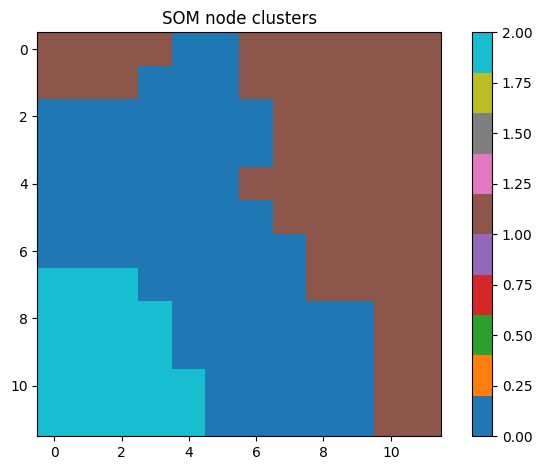

,size,risk_rate,total_clicks,active_weeks,trend,last_week
cluster,,,,,,
0,12258,0.454,5.257,0.775,-0.134,1.921
1,10826,0.275,6.593,0.975,-0.051,4.094
2,3448,0.754,2.374,0.220,-0.094,0.204


final_result,Distinction,Fail,Pass,Withdrawn
row_0,,,,
0,0.09,0.28,0.45,0.17
1,0.16,0.15,0.56,0.12
2,0.04,0.56,0.20,0.20


Chi-square test cluster vs risk: chi2 = 2563.6, p = 0.00e+00
Cluster 0: medium activity, 12258 students, risk rate 0.45
Cluster 1: high activity, 10826 students, risk rate 0.28
Cluster 2: low activity, 3448 students, risk rate 0.75


In [16]:
# Cluster the SOM nodes with k-means, choose k by silhouette, then describe clusters in domain terms
rs = np.random.default_rng(SEED); sil_idx = rs.choice(len(Xs), size=min(4000, len(Xs)), replace=False)
best = None
for k in range(3, 7):
    km = KMeans(k, n_init=10, random_state=SEED).fit(som.W)
    lab = km.labels_[bmu]
    s = silhouette_score(Xs[sil_idx], lab[sil_idx])
    print(f"k={k}: silhouette (students) = {s:.3f}")
    if best is None or s > best[0]: best = (s, k, km)
sil_best, K_SOM, km = best
node_cl = km.labels_
cl = node_cl[bmu]
print(f"Chosen k = {K_SOM}, silhouette = {sil_best:.3f}")

plt.imshow(node_cl.reshape(SOM_SIZE, SOM_SIZE), cmap="tab10"); plt.title("SOM node clusters"); plt.colorbar()
savefig("08_som_clusters")

prof = d_main["X"][som_cols].copy(); prof["cluster"] = cl; prof["risk"] = y_all
summary = prof.groupby("cluster").agg(size=("risk", "size"), risk_rate=("risk", "mean"),
                                      total_clicks=("total_clicks", "mean"), active_weeks=("active_weeks", "mean"),
                                      trend=("trend", "mean"), last_week=("last_week_clicks", "mean")).round(3)
display(summary)
display(pd.crosstab(cl, d_main["meta"]["final_result"], normalize="index").round(2))
chi2, pval, _, _ = stats.chi2_contingency(pd.crosstab(cl, y_all))
print(f"Chi-square test cluster vs risk: chi2 = {chi2:.1f}, p = {pval:.2e}")
z = (summary["total_clicks"] - summary["total_clicks"].mean()) / summary["total_clicks"].std()
for c_ in summary.index:
    lvl = "high" if z[c_] > 0.5 else "low" if z[c_] < -0.5 else "medium"
    print(f"Cluster {c_}: {lvl} activity, {int(summary.loc[c_, 'size'])} students, risk rate {summary.loc[c_, 'risk_rate']:.2f}")
log_custom("som", "Kohonen SOM", N_MAIN, {"grid": SOM_SIZE, "epochs": SOM_EPOCHS, "k_clusters": K_SOM},
           quantization_error=qe, topographic_error=te_, silhouette=float(sil_best), chi2_p=float(pval))
save_log()

10. Elective experiment: Counterpropagation network (CPN)

In [17]:
class CounterpropagationNet:
    def __init__(self, n_units=100, alpha0=0.3, alpha_end=0.01, beta=0.05, epochs_kohonen=5, epochs_grossberg=3, seed=SEED):
        self.K, self.a0, self.a1, self.beta = n_units, alpha0, alpha_end, beta
        self.ek, self.eg, self.rng = epochs_kohonen, epochs_grossberg, np.random.default_rng(seed)

    def winners(self, X):
        d = (X ** 2).sum(1)[:, None] - 2 * X @ self.W.T + (self.W ** 2).sum(1)[None, :]
        return d.argmin(1)

    def fit(self, X, y):
        n = len(X)
        self.W = X[self.rng.choice(n, self.K, replace=n < self.K)].copy()
        total, t = self.ek * n, 0
        for _ in range(self.ek):                                   # layer 1: competitive learning
            for i in self.rng.permutation(n):
                alpha = self.a0 * (self.a1 / self.a0) ** (t / total)
                j = int(np.argmin(((self.W - X[i]) ** 2).sum(1)))
                self.W[j] += alpha * (X[i] - self.W[j]); t += 1
        win = self.winners(X)                                      # layer 2: outstar learning
        self.V = np.full(self.K, 0.5); seen = np.zeros(self.K, bool)
        for _ in range(self.eg):
            for i in self.rng.permutation(n):
                j = win[i]
                if not seen[j]: self.V[j] = y[i]; seen[j] = True
                else: self.V[j] += self.beta * (y[i] - self.V[j])
        return self

    def predict_proba(self, X): return self.V[self.winners(X)]

def fp_cpn(n_units):
    def fp(data, tr, te, seed):
        tr_in, va_in = inner_val_split(tr, data["y"], data["groups"], seed)
        (Xtr, Xva, Xte), _ = prep_tabular(data, [tr_in, va_in, te])
        m = CounterpropagationNet(n_units, epochs_kohonen=1 if QUICK_RUN else 5, seed=seed).fit(Xtr, data["y"][tr_in])
        return m.predict_proba(Xte), {"val_auc": roc_auc_score(data["y"][va_in], m.predict_proba(Xva))}
    return fp

cpn_rows = {}
for K_ in ([25, 100] if QUICK_RUN else [25, 100, 400]):
    res = run_and_log("cpn", f"CPN:{K_} units", fp_cpn(K_), d_main, {"n_units": K_})
    cpn_rows[K_] = res["val_auc"].mean()
BEST_CPN_K = max(cpn_rows, key=cpn_rows.get)
RESULTS[("CPN", N_MAIN)] = RESULTS[(f"CPN:{BEST_CPN_K} units", N_MAIN)]
print("Best CPN size by validation AUC:", BEST_CPN_K); save_log()

CPN:25 units             weeks=8   AUC 0.713 ± 0.010 | F1 0.549 ± 0.023 | 64s
CPN:100 units            weeks=8   AUC 0.728 ± 0.003 | F1 0.574 ± 0.010 | 64s
CPN:400 units            weeks=8   AUC 0.736 ± 0.005 | F1 0.580 ± 0.005 | 79s
Best CPN size by validation AUC: 400


11. Gradient descent variants and optimizers

batch GD (bs = n)      final val loss 0.6768 | val AUC 0.621 | time 0.2s
mini-batch (bs = 64)   final val loss 0.5717 | val AUC 0.758 | time 0.6s
stochastic (bs = 1)    final val loss 0.5953 | val AUC 0.743 | time 28.5s


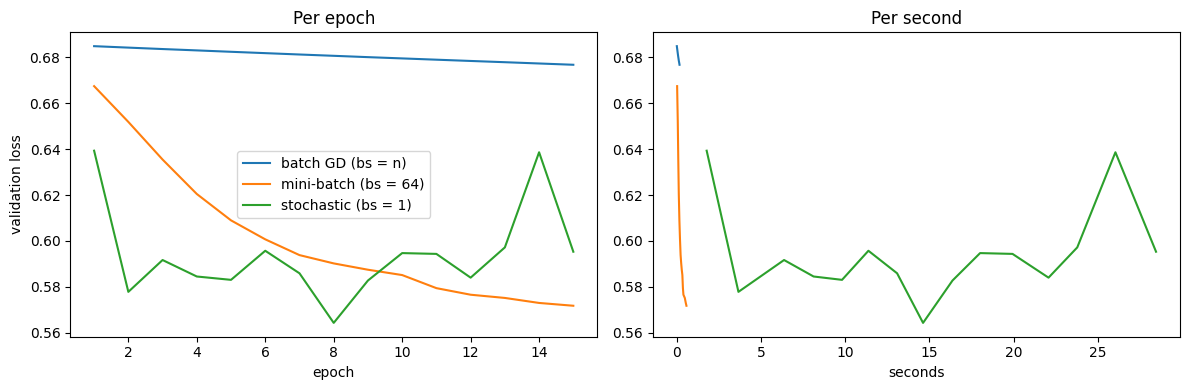

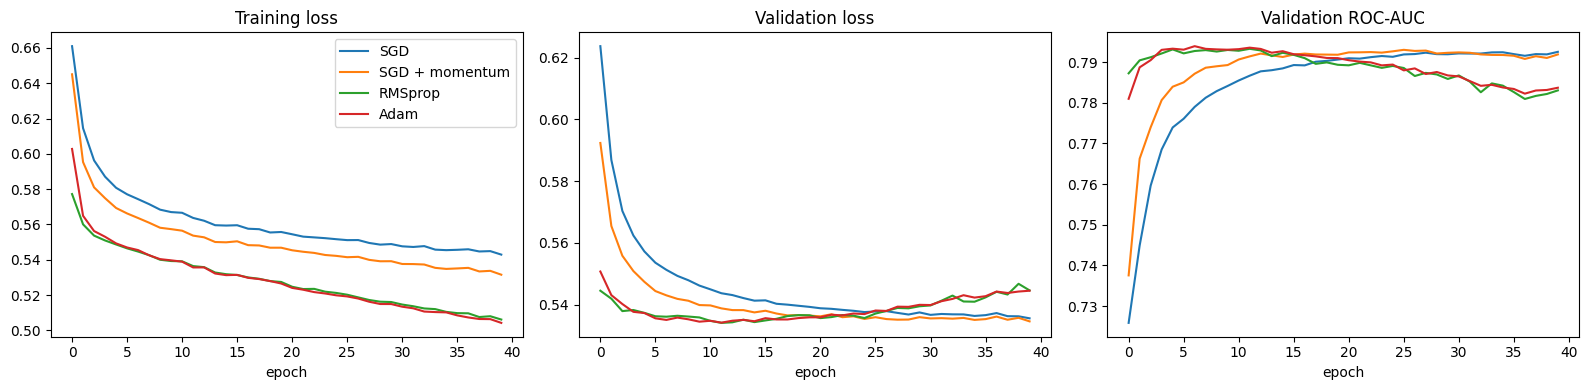

,best val loss,epoch of best,best val AUC
SGD,0.5355,40.0,0.7925
SGD + momentum,0.5346,40.0,0.7930
RMSprop,0.5341,12.0,0.7933
Adam,0.5341,12.0,0.7939


In [18]:
tr0, te0 = get_folds(d_main)[0]
tr_in, va_in = inner_val_split(tr0, d_main["y"], d_main["groups"], SEED)
(Xtr, Xva, Xte), _ = prep_tabular(d_main, [tr_in, va_in, te0])
ytr, yva = d_main["y"][tr_in], d_main["y"][va_in]
arch = BEST_MLP["arch"]

# ---- Part A: batch vs stochastic vs mini-batch ----
sub = np.random.default_rng(SEED).choice(len(Xtr), size=min(2000, len(Xtr)), replace=False)
variants = {"batch GD (bs = n)": len(sub), "mini-batch (bs = 64)": 64, "stochastic (bs = 1)": 1}
histA = {}
for name, bs in variants.items():
    set_seed(SEED)
    m = MLP(Xtr.shape[1], **arch)
    _, h = train_torch(m, [Xtr[sub]], ytr[sub], [Xva], yva, optimizer="sgd", lr=0.05, batch_size=bs,
                       epochs=GD_EPOCHS, patience=10 ** 9, seed=SEED)
    histA[name] = h
    print(f"{name:<22} final val loss {h['val_loss'][-1]:.4f} | val AUC {h['val_auc'][-1]:.3f} | time {h['time'][-1]:.1f}s")
    log_custom("gradient_descent", name, N_MAIN, {"lr": 0.05, "epochs": GD_EPOCHS, "subset": len(sub)},
               val_loss=h["val_loss"][-1], val_auc=h["val_auc"][-1], seconds=h["time"][-1])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, h in histA.items():
    ax[0].plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], label=name)
    ax[1].plot(h["time"], h["val_loss"], label=name)
ax[0].set_xlabel("epoch"); ax[1].set_xlabel("seconds"); ax[0].set_ylabel("validation loss"); ax[0].legend()
ax[0].set_title("Per epoch"); ax[1].set_title("Per second")
savefig("09_gradient_descent_variants")

# ---- Part B: optimizers ----
OPTS = {"SGD": ("sgd", 0.05), "SGD + momentum": ("momentum", 0.01), "RMSprop": ("rmsprop", 1e-3), "Adam": ("adam", 1e-3)}
curves = {}
for name, (opt, lr) in OPTS.items():
    hs = []
    for s in OPT_SEEDS:
        set_seed(s)
        m = MLP(Xtr.shape[1], **arch)
        _, h = train_torch(m, [Xtr], ytr, [Xva], yva, optimizer=opt, lr=lr, batch_size=128,
                           epochs=OPT_EPOCHS, patience=10 ** 9, seed=s)
        hs.append(h)
    curves[name] = {k: np.mean([h[k] for h in hs], axis=0) for k in ("train_loss", "val_loss", "val_auc")}
    log_custom("optimizers", name, N_MAIN, {"lr": lr, "batch_size": 128, "epochs": OPT_EPOCHS, "seeds": len(OPT_SEEDS)},
               val_loss=float(curves[name]["val_loss"].min()), val_auc=float(curves[name]["val_auc"].max()))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for name, c in curves.items():
    ax[0].plot(c["train_loss"], label=name); ax[1].plot(c["val_loss"], label=name); ax[2].plot(c["val_auc"], label=name)
for a_, t in zip(ax, ("Training loss", "Validation loss", "Validation ROC-AUC")):
    a_.set_title(t); a_.set_xlabel("epoch")
ax[0].legend(); savefig("10_optimizer_learning_curves")
display(pd.DataFrame({n: {"best val loss": c["val_loss"].min(), "epoch of best": int(c["val_loss"].argmin()) + 1,
                          "best val AUC": c["val_auc"].max()} for n, c in curves.items()}).T.round(4))
save_log()

12. 1D-CNN on the weekly sequence

In [19]:
STATIC_COLS = DEMO_NUM + CAT_COLS

def fp_cnn(cfg):
    def fp(data, tr, te, seed):
        set_seed(seed)
        tr_in, va_in = inner_val_split(tr, data["y"], data["groups"], seed)
        S = data["seq"]
        mu = S[tr_in].mean(axis=(0, 2), keepdims=True); sd = S[tr_in].std(axis=(0, 2), keepdims=True) + 1e-6
        Str, Sva, Ste = [((S[i] - mu) / sd).astype(np.float32) for i in (tr_in, va_in, te)]
        pre = build_preprocessor(DEMO_NUM, CAT_COLS)
        Ztr = pre.fit_transform(data["X"].iloc[tr_in][STATIC_COLS]).astype(np.float32)
        Zva = pre.transform(data["X"].iloc[va_in][STATIC_COLS]).astype(np.float32)
        Zte = pre.transform(data["X"].iloc[te][STATIC_COLS]).astype(np.float32)
        model = CNN1D(S.shape[1], Ztr.shape[1], **cfg["arch"])
        model, hist = train_torch(model, [Str, Ztr], data["y"][tr_in], [Sva, Zva], data["y"][va_in],
                                  optimizer="adam", lr=cfg.get("lr", 1e-3), weight_decay=cfg.get("weight_decay", 1e-4),
                                  batch_size=256, seed=seed)
        return predict_proba_torch(model, [Ste, Zte]), {"val_auc": hist["best_val_auc"], "best_epoch": hist["best_epoch"]}
    return fp

CNN_CONFIGS = {
    "base (32 filters, k=3)": {"arch": {"n_filters": 32, "kernel_size": 3, "dropout": 0.3}},
    "kernel 5": {"arch": {"n_filters": 32, "kernel_size": 5, "dropout": 0.3}},
    "64 filters": {"arch": {"n_filters": 64, "kernel_size": 3, "dropout": 0.3}},
}
rows = []
for name, cfg in CNN_CONFIGS.items():
    res = run_and_log("cnn_experiments", f"CNN1D:{name}", fp_cnn(cfg), d_main, cfg)
    rows.append({"config": name, "val_auc": res["val_auc"].mean(), "test_auc": ms(res, "roc_auc"), "test_f1": ms(res, "f1")})
cnn_table = pd.DataFrame(rows).set_index("config"); display(cnn_table.round(4))
BEST_CNN_NAME = cnn_table["val_auc"].idxmax(); BEST_CNN = CNN_CONFIGS[BEST_CNN_NAME]
print("Best CNN by validation AUC:", BEST_CNN_NAME)
RESULTS[("CNN1D", N_MAIN)] = RESULTS[(f"CNN1D:{BEST_CNN_NAME}", N_MAIN)]
save_log()

CNN1D:base (32 filters, k=3) weeks=8   AUC 0.784 ± 0.003 | F1 0.633 ± 0.014 | 94s
CNN1D:kernel 5           weeks=8   AUC 0.784 ± 0.004 | F1 0.633 ± 0.005 | 92s
CNN1D:64 filters         weeks=8   AUC 0.784 ± 0.004 | F1 0.641 ± 0.011 | 101s


,val_auc,test_auc,test_f1
config,,,
"base (32 filters, k=3)",0.7868,0.784 ± 0.003,0.633 ± 0.014
kernel 5,0.7913,0.784 ± 0.004,0.633 ± 0.005
64 filters,0.7885,0.784 ± 0.004,0.641 ± 0.011


Best CNN by validation AUC: kernel 5


13. Final comparison of all models

MLP                      weeks=4   AUC 0.750 ± 0.008 | F1 0.615 ± 0.010 | 76s
CNN1D                    weeks=4   AUC 0.750 ± 0.007 | F1 0.618 ± 0.008 | 99s
MLP                      weeks=12  AUC 0.800 ± 0.009 | F1 0.633 ± 0.009 | 73s
CNN1D                    weeks=12  AUC 0.799 ± 0.008 | F1 0.636 ± 0.008 | 90s


,roc_auc,f1,precision,recall,accuracy
model,,,,,
LogReg,0.781 ± 0.004,0.631 ± 0.005,0.711 ± 0.004,0.568 ± 0.008,0.721 ± 0.003
RandForest,0.777 ± 0.006,0.613 ± 0.002,0.724 ± 0.004,0.531 ± 0.002,0.718 ± 0.002
MLP,0.784 ± 0.005,0.623 ± 0.007,0.721 ± 0.008,0.549 ± 0.009,0.721 ± 0.005
CNN1D,0.784 ± 0.004,0.633 ± 0.005,0.720 ± 0.018,0.565 ± 0.018,0.724 ± 0.004
CPN,0.736 ± 0.005,0.580 ± 0.005,0.676 ± 0.021,0.510 ± 0.018,0.691 ± 0.006


Best model by mean ROC-AUC: CNN1D


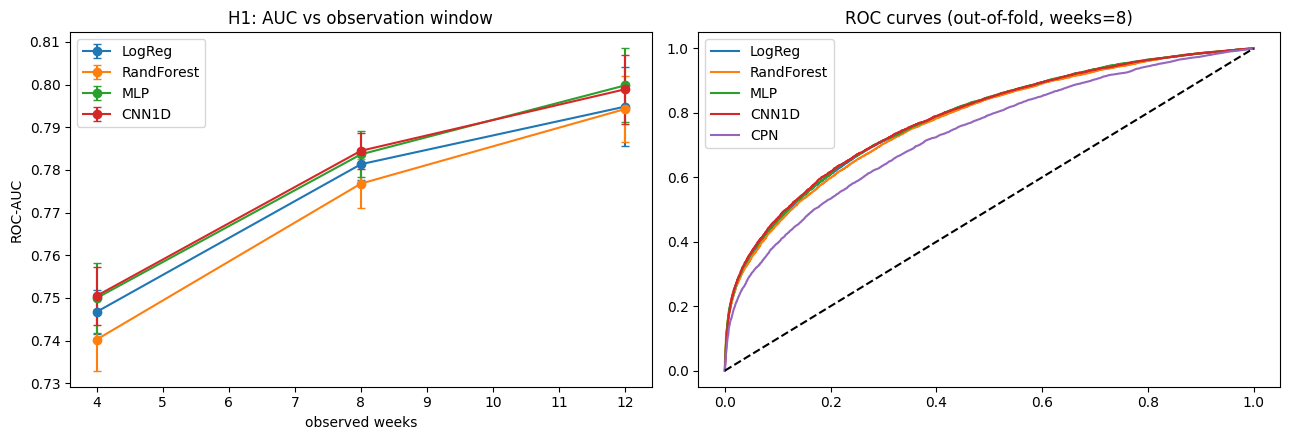


H1 check (mean AUC over the 4 models):
  weeks 4 -> 8: AUC gain = +0.0347
  weeks 8 -> 12: AUC gain = +0.0154

H2 check (paired t-test over folds, CNN1D vs MLP, ROC-AUC; only 5 folds, so low power):
  weeks=4: CNN 0.7505 vs MLP 0.7500 | diff +0.0005 | p = 0.766
  weeks=8: CNN 0.7845 vs MLP 0.7836 | diff +0.0008 | p = 0.564
  weeks=12: CNN 0.7989 vs MLP 0.7998 | diff -0.0009 | p = 0.520


In [20]:
for N in N_WEEKS_LIST:
    if ("MLP", N) not in RESULTS: run_and_log("final_comparison", "MLP", fp_mlp(BEST_MLP), DATA[N], BEST_MLP)
    if ("CNN1D", N) not in RESULTS: run_and_log("final_comparison", "CNN1D", fp_cnn(BEST_CNN), DATA[N], BEST_CNN)

MODELS = ["LogReg", "RandForest", "MLP", "CNN1D", "CPN"]
rows = []
for m in MODELS:
    f = RESULTS[(m, N_MAIN)]["folds"]
    rows.append({"model": m, **{k: ms(f, k) for k in METRICS}, "auc_mean": f["roc_auc"].mean()})
comp = pd.DataFrame(rows).set_index("model")
display(comp.drop(columns="auc_mean"))
comp.drop(columns="auc_mean").to_csv(OUT_DIR / f"comparison_table_weeks{N_MAIN}.csv")
BEST_MODEL = comp["auc_mean"].idxmax(); print("Best model by mean ROC-AUC:", BEST_MODEL)

# H1: effect of the number of weeks
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for m in ["LogReg", "RandForest", "MLP", "CNN1D"]:
    mu = [RESULTS[(m, N)]["folds"]["roc_auc"].mean() for N in N_WEEKS_LIST]
    sd = [RESULTS[(m, N)]["folds"]["roc_auc"].std() for N in N_WEEKS_LIST]
    ax[0].errorbar(N_WEEKS_LIST, mu, yerr=sd, marker="o", capsize=3, label=m)
ax[0].set_xlabel("observed weeks"); ax[0].set_ylabel("ROC-AUC"); ax[0].set_title("H1: AUC vs observation window"); ax[0].legend()
for m in MODELS:
    fpr, tpr, _ = roc_curve(d_main["y"], RESULTS[(m, N_MAIN)]["oof"]); ax[1].plot(fpr, tpr, label=m)
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title(f"ROC curves (out-of-fold, weeks={N_MAIN})"); ax[1].legend()
savefig("11_comparison")

print("\nH1 check (mean AUC over the 4 models):")
auc_by_N = {N: np.mean([RESULTS[(m, N)]["folds"]["roc_auc"].mean() for m in ["LogReg", "RandForest", "MLP", "CNN1D"]]) for N in N_WEEKS_LIST}
for a_, b_ in zip(N_WEEKS_LIST[:-1], N_WEEKS_LIST[1:]):
    print(f"  weeks {a_} -> {b_}: AUC gain = {auc_by_N[b_] - auc_by_N[a_]:+.4f}")
print("\nH2 check (paired t-test over folds, CNN1D vs MLP, ROC-AUC; only 5 folds, so low power):")
for N in N_WEEKS_LIST:
    a_ = RESULTS[("CNN1D", N)]["folds"]["roc_auc"].values; b_ = RESULTS[("MLP", N)]["folds"]["roc_auc"].values
    t_, p_ = stats.ttest_rel(a_, b_)
    print(f"  weeks={N}: CNN {a_.mean():.4f} vs MLP {b_.mean():.4f} | diff {a_.mean() - b_.mean():+.4f} | p = {p_:.3f}")
save_log()

14. Error analysis

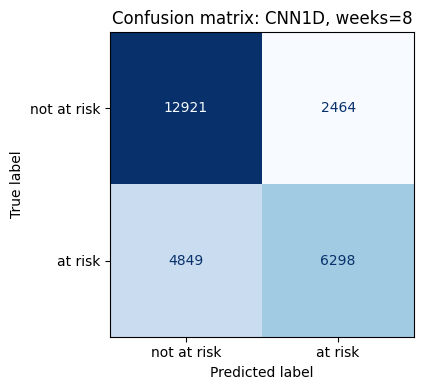

Error rates by module:


,n,risk_rate,miss_rate_FN,false_alarm_FP
code_module,,,,
AAA,707,0.249,0.191,0.048
BBB,6256,0.400,0.196,0.077
CCC,3242,0.482,0.173,0.123
DDD,5053,0.483,0.181,0.111
EEE,2490,0.337,0.169,0.063
FFF,6377,0.428,0.170,0.091
GGG,2407,0.371,0.210,0.103


Error rates by early activity level:


,n,risk_rate,miss_rate_FN,false_alarm_FP
activity_quartile,,,,
Q1 lowest,6656,0.629,0.119,0.141
Q2,6617,0.460,0.199,0.118
Q3,6632,0.348,0.216,0.082
Q4 highest,6627,0.243,0.197,0.031


Missed at-risk students (false negatives) by final result:
{'Fail': 2930, 'Withdrawn': 1919}


,missed (FN),found (TP)
total_clicks,5.763,4.129
mean_weekly_clicks,3.145,1.574
std_weekly_clicks,1.141,1.222
last_week_clicks,2.967,1.013
active_weeks,0.862,0.519


In [21]:
oof = RESULTS[(BEST_MODEL, N_MAIN)]["oof"]; y = d_main["y"]; pred = (oof >= 0.5).astype(int)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=["not at risk", "at risk"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion matrix: {BEST_MODEL}, weeks={N_MAIN}"); savefig("12_confusion_matrix")

err = d_main["meta"].copy(); err["y"] = y; err["pred"] = pred
err["fn"] = ((y == 1) & (pred == 0)).astype(int); err["fp"] = ((y == 0) & (pred == 1)).astype(int)
err["activity_quartile"] = pd.qcut(d_main["X"]["total_clicks"], 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"], duplicates="drop")
print("Error rates by module:"); display(err.groupby("code_module").agg(n=("y", "size"), risk_rate=("y", "mean"), miss_rate_FN=("fn", "mean"), false_alarm_FP=("fp", "mean")).round(3))
print("Error rates by early activity level:"); display(err.groupby("activity_quartile").agg(n=("y", "size"), risk_rate=("y", "mean"), miss_rate_FN=("fn", "mean"), false_alarm_FP=("fp", "mean")).round(3))
print("Missed at-risk students (false negatives) by final result:"); print(err[err["fn"] == 1]["final_result"].value_counts().to_dict())
fnx = d_main["X"][err["fn"] == 1][d_main["beh_cols"][:5]].mean(); tpx = d_main["X"][(y == 1) & (pred == 1)][d_main["beh_cols"][:5]].mean()
display(pd.DataFrame({"missed (FN)": fnx, "found (TP)": tpx}).round(3))

15. Final hold-out training and saving models

In [22]:
d = d_main; y = d["y"]; g = d["groups"]
sg = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
rest, test_idx = next(sg.split(np.zeros(len(y)), y, g))
train_idx, val_idx = inner_val_split(rest, y, g, SEED)
print(f"train {len(train_idx)} | val {len(val_idx)} | test {len(test_idx)}")
Xdf = d["X"]; FEATURE_COLS = list(Xdf.columns); PRED, HOLD = {}, {}

# LogReg and RF (train + validation)
tv = np.concatenate([train_idx, val_idx]); SK = {}
for name, mk_ in (("LogReg", make_lr), ("RandForest", make_rf)):
    pipe = Pipeline([("pre", build_preprocessor(d["num_cols"], d["cat_cols"])), ("clf", mk_(SEED))]).fit(Xdf.iloc[tv], y[tv])
    SK[name] = pipe; PRED[name] = (lambda X_, S_, p=pipe: p.predict_proba(X_[FEATURE_COLS])[:, 1])
    joblib.dump(pipe, MODEL_DIR / f"{name.lower()}_pipeline.joblib")

# MLP
set_seed(SEED)
(Xtr_, Xva_, Xte_), pre_nn = prep_tabular(d, [train_idx, val_idx, test_idx])
mlp_final, _ = train_torch(MLP(Xtr_.shape[1], **BEST_MLP["arch"]), [Xtr_], y[train_idx], [Xva_], y[val_idx],
                           optimizer="adam", lr=BEST_MLP["lr"], weight_decay=BEST_MLP["weight_decay"], seed=SEED)
PRED["MLP"] = lambda X_, S_: predict_proba_torch(mlp_final, [pre_nn.transform(X_[FEATURE_COLS]).astype(np.float32)])
torch.save(mlp_final.state_dict(), MODEL_DIR / "mlp_weights.pt"); joblib.dump(pre_nn, MODEL_DIR / "preprocessor_tabular.joblib")

# CNN
set_seed(SEED)
S = d["seq"]; mu_s = S[train_idx].mean(axis=(0, 2), keepdims=True); sd_s = S[train_idx].std(axis=(0, 2), keepdims=True) + 1e-6
pre_st = build_preprocessor(DEMO_NUM, CAT_COLS); pre_st.fit(Xdf.iloc[train_idx][STATIC_COLS])
def cnn_inputs(X_, S_):
    return [((S_ - mu_s) / sd_s).astype(np.float32), pre_st.transform(X_[STATIC_COLS]).astype(np.float32)]
cnn_final, _ = train_torch(CNN1D(S.shape[1], pre_st.transform(Xdf.iloc[:2][STATIC_COLS]).shape[1], **BEST_CNN["arch"]),
                           cnn_inputs(Xdf.iloc[train_idx], S[train_idx]), y[train_idx],
                           cnn_inputs(Xdf.iloc[val_idx], S[val_idx]), y[val_idx], optimizer="adam", lr=1e-3, weight_decay=1e-4, seed=SEED)
PRED["CNN1D"] = lambda X_, S_: predict_proba_torch(cnn_final, cnn_inputs(X_, S_))
torch.save(cnn_final.state_dict(), MODEL_DIR / "cnn1d_weights.pt")
joblib.dump({"mu": mu_s, "sd": sd_s, "pre_static": pre_st}, MODEL_DIR / "cnn_scalers.joblib")

Xtest, Stest, ytest = Xdf.iloc[test_idx], S[test_idx], y[test_idx]
rows = []
for name, fn in PRED.items():
    HOLD[name] = fn(Xtest, Stest); rows.append({"model": name, **evaluate(ytest, HOLD[name])})
hold = pd.DataFrame(rows).set_index("model").round(4); display(hold); hold.to_csv(OUT_DIR / "holdout_results.csv")
for name, r in hold.iterrows():
    log_custom("holdout", name, N_MAIN, {"split": "70/15/15 grouped"}, **{k + "_mean": v for k, v in r.items()})

cfg_out = {"weeks": N_MAIN, "feature_columns": FEATURE_COLS, "num_cols": d["num_cols"], "cat_cols": d["cat_cols"],
           "mlp_arch": BEST_MLP["arch"], "cnn_arch": BEST_CNN["arch"], "channels": CH_NAMES, "activity_groups": ACT_NAMES,
           "in_dim_mlp": int(Xtr_.shape[1])}
json.dump(cfg_out, open(MODEL_DIR / "config.json", "w"), indent=2)
Xdf.iloc[test_idx[:20]].to_csv(MODEL_DIR / "sample_input.csv", index=False)
save_log()

train 18951 | val 3791 | test 3790


,roc_auc,f1,precision,recall,accuracy
model,,,,,
LogReg,0.7689,0.6206,0.6936,0.5616,0.7116
RandForest,0.7586,0.6004,0.6974,0.5270,0.7053
MLP,0.7680,0.6129,0.6821,0.5565,0.7047
CNN1D,0.7713,0.6295,0.6912,0.5779,0.7142


16. Explainability (XAI)

Holdout AUC by model: {'LogReg': 0.7689, 'RandForest': 0.7586, 'MLP': 0.768, 'CNN1D': 0.7713} | model used for permutation importance: CNN1D


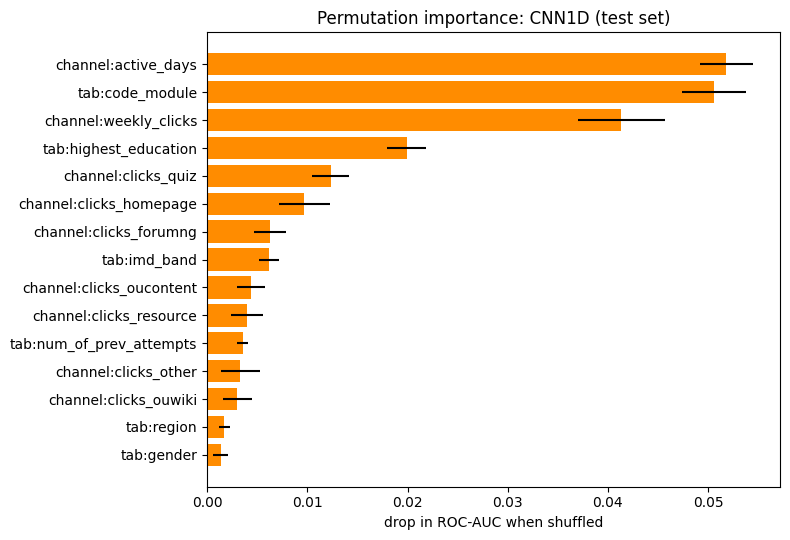

,feature,auc_drop,sd
11,channel:active_days,0.0518,0.0026
3,tab:code_module,0.0506,0.0032
10,channel:weekly_clicks,0.0413,0.0044
6,tab:highest_education,0.0199,0.0019
15,channel:clicks_quiz,0.0123,0.0019
14,channel:clicks_homepage,0.0097,0.0026
12,channel:clicks_forumng,0.0063,0.0016
7,tab:imd_band,0.0061,0.0010
13,channel:clicks_oucontent,0.0043,0.0014
17,channel:clicks_resource,0.0040,0.0016


SHAP model: LogReg


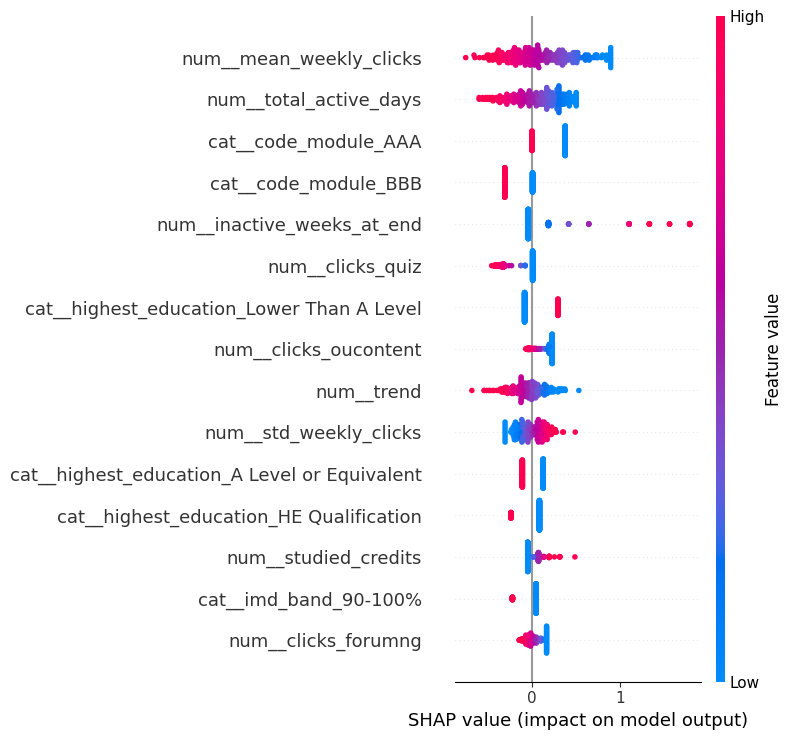

Top features by mean |SHAP|: {'num__mean_weekly_clicks': 0.2977, 'num__total_active_days': 0.2374, 'cat__code_module_AAA': 0.227, 'cat__code_module_BBB': 0.1902, 'num__inactive_weeks_at_end': 0.1867, 'num__clicks_quiz': 0.1864, 'cat__highest_education_Lower Than A Level': 0.1605, 'num__clicks_oucontent': 0.1463}

Plausibility check (Spearman: feature value vs SHAP value; negative = higher value lowers risk):
  num__mean_weekly_clicks          rho = -1.00
  num__total_active_days           rho = -1.00
  cat__code_module_AAA             rho = -1.00
  cat__code_module_BBB             rho = -1.00
  num__inactive_weeks_at_end       rho = +1.00
  num__clicks_quiz                 rho = -1.00


In [23]:
best_hold = hold["roc_auc"].idxmax()
xai_model = BEST_MODEL if BEST_MODEL in PRED else best_hold
print("Holdout AUC by model:", hold["roc_auc"].to_dict(), "| model used for permutation importance:", xai_model)

def perm_importance(predict, Xdf_, seq_, y_, specs, n_repeats=5, seed=SEED):
    base = roc_auc_score(y_, predict(Xdf_, seq_)); rng = np.random.default_rng(seed); out = []
    for kind, nm in specs:
        drops = []
        for _ in range(n_repeats):
            p = rng.permutation(len(y_))
            if kind == "tab":
                Xp = Xdf_.copy(); Xp[nm] = Xdf_[nm].values[p]; Sp = seq_
            else:
                Xp = Xdf_; Sp = seq_.copy(); Sp[:, nm, :] = seq_[p][:, nm, :]
            drops.append(base - roc_auc_score(y_, predict(Xp, Sp)))
        out.append((f"{kind}:{nm}" if kind == "tab" else f"channel:{CH_NAMES[nm]}", np.mean(drops), np.std(drops)))
    return pd.DataFrame(out, columns=["feature", "auc_drop", "sd"]).sort_values("auc_drop", ascending=False)

if xai_model == "CNN1D":
    specs = [("tab", c) for c in STATIC_COLS] + [("chan", i) for i in range(len(CH_NAMES))]
else:
    specs = [("tab", c) for c in FEATURE_COLS]
pi = perm_importance(PRED[xai_model], Xtest, Stest, ytest, specs, n_repeats=2 if QUICK_RUN else 5)
top = pi.head(15).iloc[::-1]
plt.figure(figsize=(8, 5.5)); plt.barh(top["feature"], top["auc_drop"], xerr=top["sd"], color="darkorange")
plt.xlabel("drop in ROC-AUC when shuffled"); plt.title(f"Permutation importance: {xai_model} (test set)")
savefig("13_permutation_importance"); display(pi.head(10).round(4))

# ---- SHAP on the best tabular model ----
tab_best = hold.loc[[m for m in ("LogReg", "RandForest", "MLP")]]["roc_auc"].idxmax()
print("SHAP model:", tab_best)
try:
    import shap
    n_exp = 100 if QUICK_RUN else 300
    if tab_best == "MLP":
        Xt_all = pre_nn.transform(Xtest).astype(np.float32); names = pre_nn.get_feature_names_out()
        f_ = lambda a: predict_proba_torch(mlp_final, [a.astype(np.float32)])
        ex = shap.KernelExplainer(f_, shap.kmeans(Xtr_, 15))
        Xe = Xt_all[:min(n_exp, 100)]; sv = ex.shap_values(Xe, nsamples=100 if QUICK_RUN else 200)
    else:
        pipe = SK[tab_best]; pre_ = pipe.named_steps["pre"]; clf = pipe.named_steps["clf"]
        names = pre_.get_feature_names_out(); Xe = pre_.transform(Xtest.iloc[:n_exp])
        if tab_best == "RandForest":
            sv = shap.TreeExplainer(clf).shap_values(Xe)
        else:
            sv = shap.LinearExplainer(clf, pre_.transform(Xdf.iloc[train_idx[:500]])).shap_values(Xe)
    if isinstance(sv, list): sv = sv[1]
    sv = np.asarray(sv)
    if sv.ndim == 3: sv = sv[:, :, 1]
    shap.summary_plot(sv, Xe, feature_names=list(names), show=False, max_display=15)
    savefig("14_shap_summary")
    imp = pd.Series(np.abs(sv).mean(0), index=names).sort_values(ascending=False).head(8)
    print("Top features by mean |SHAP|:", imp.round(4).to_dict())
    print("\nPlausibility check (Spearman: feature value vs SHAP value; negative = higher value lowers risk):")
    for f_name in imp.index[:6]:
        j = list(names).index(f_name); rho = stats.spearmanr(Xe[:, j], sv[:, j]).correlation
        print(f"  {f_name:<32} rho = {rho:+.2f}")
except ImportError:
    print("shap is not installed: pip install shap")

17. Reproducibility files

In [24]:
%%writefile inference.py
"""Score students with the saved MLP. Usage: python inference.py models_saved/sample_input.csv predictions.csv"""
import sys, json
import numpy as np, pandas as pd, torch, joblib
from models import MLP

inp = sys.argv[1] if len(sys.argv) > 1 else "models_saved/sample_input.csv"
out = sys.argv[2] if len(sys.argv) > 2 else "predictions.csv"
cfg = json.load(open("models_saved/config.json"))
pre = joblib.load("models_saved/preprocessor_tabular.joblib")
model = MLP(cfg["in_dim_mlp"], **cfg["mlp_arch"])
model.load_state_dict(torch.load("models_saved/mlp_weights.pt", map_location="cpu"))
model.eval()

df = pd.read_csv(inp)
X = pre.transform(df[cfg["feature_columns"]]).astype(np.float32)
with torch.no_grad():
    p = torch.sigmoid(model(torch.tensor(X))).numpy()
pd.DataFrame({"risk_probability": p, "at_risk": (p >= 0.5).astype(int)}).to_csv(out, index=False)
print(f"Saved {len(p)} predictions to {out} (weeks of data used: {cfg['weeks']})")

Writing inference.py


In [25]:
pkgs = ["numpy", "pandas", "scikit-learn", "torch", "matplotlib", "scipy", "joblib", "shap", "umap-learn"]
lines = []
for p in pkgs:
    try: lines.append(f"{p}=={importlib.metadata.version(p)}")
    except importlib.metadata.PackageNotFoundError: pass
Path("requirements.txt").write_text("\n".join(lines) + "\n")
Path("README.md").write_text("""# Early prediction of student risk from weekly clickstream (OULAD)

Final project, AI and Neural Networks. Thesis: An Intelligent System for Predicting Students' Learning Activity
in Educational Platforms Using Big Data Technologies.

## Run
1. `pip install -r requirements.txt`
2. Open `final_project.ipynb` and run all cells. OULAD (CC BY 4.0) is downloaded automatically into `data/oulad/`
   (or download it from https://analyse.kmi.open.ac.uk/open_dataset and put the csv files there).
   Set the environment variable `QUICK_RUN=1` for a fast test run.
3. Score new students: `python inference.py models_saved/sample_input.csv predictions.csv`

## Files
- `final_project.ipynb`: all stages (data, baselines, MLP, SOM, CPN, optimizers, CNN, evaluation, XAI)
- `models.py`: PyTorch MLP and 1D-CNN
- `inference.py`: scoring script (MLP)
- `models_saved/`: trained weights, preprocessors, config
- `results/`: experiment log (`experiment_log.csv`), tables, figures

Random seed: 42 (Python, NumPy, PyTorch). Splits are grouped by student.
""")
print(open("requirements.txt").read())
save_log()
log = pd.DataFrame(EXP_LOG); print("Experiments logged:", len(log))
log[["timestamp", "stage", "model", "weeks"] + [c for c in ("roc_auc_mean", "roc_auc_std", "f1_mean") if c in log]].tail(12)

numpy==2.3.5
pandas==2.3.3
scikit-learn==1.9.0
torch==2.10.0
matplotlib==3.10.9
scipy==1.16.3
joblib==1.5.2
shap==0.51.0
umap-learn==0.5.12

Experiments logged: 40


,timestamp,stage,model,weeks,roc_auc_mean,roc_auc_std,f1_mean
28,2026-10-25T23:34:01,optimizers,Adam,8,NaN,NaN,NaN
29,2026-10-25T23:35:35,cnn_experiments,"CNN1D:base (32 filters, k=3)",8,0.783538,0.003430,0.632903
30,2026-10-25T23:37:08,cnn_experiments,CNN1D:kernel 5,8,0.784483,0.004190,0.632590
31,2026-10-25T23:38:48,cnn_experiments,CNN1D:64 filters,8,0.783683,0.003840,0.640766
32,2026-10-25T23:40:04,final_comparison,MLP,4,0.749979,0.008187,0.615494
33,2026-10-25T23:41:43,final_comparison,CNN1D,4,0.750493,0.006784,0.618353
34,2026-10-25T23:42:55,final_comparison,MLP,12,0.799810,0.008648,0.632983
35,2026-10-25T23:44:25,final_comparison,CNN1D,12,0.798898,0.008117,0.635568
36,2026-10-25T23:45:04,holdout,LogReg,8,0.768900,NaN,0.620600
37,2026-10-25T23:45:04,holdout,RandForest,8,0.758600,NaN,0.600400
